# CEDS release time series

Annual global and sectoral totals for each CEDS release, and the differences
between them. Answers: how have CMIP7 CEDS emissions changed relative to CMIP6
and across the CMIP7 release series?

Prerequisite: `01_inventory.ipynb` must pass for every release used here.

Comparable window is set by the shortest release (CEDS-2017 ends 2014), not
assumed. Sector definitions are identical across all releases compared here —
verified in notebook 01 — so sectoral differencing is valid.

In [1]:
from pathlib import Path
import sys
import warnings

warnings.filterwarnings("ignore", module="argopy")

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src" / "slcf_forcings").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate src/slcf_forcings above cwd")
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from slcf_forcings.ceds import select_files, load_cell_area, annual_global_totals, cell_area_from_grid
from slcf_forcings.compare import align_releases
from slcf_forcings.paths import CEDS

OUT = PROJECT_ROOT / "output" / "timeseries"
OUT.mkdir(parents=True, exist_ok=True)

# Releases to aggregate. Each entry carries the kwargs select_files needs,
# because the archive spans two publication version directories.

RELEASES = {
    "cmip6":       dict(data_dir=CEDS["cmip6"],       allow_multiple_versions=True),
    "preprod_nov": dict(data_dir=CEDS["preprod_nov"], allow_multiple_versions=True,
                        require_all=False),   # no NMVOC in this release
    "archive":     dict(data_dir=CEDS["archive"],     allow_multiple_versions=True),
    "production":  dict(data_dir=CEDS["production"],  version="v20250421"),
}

SPECIES = ["SO2", "BC", "OC", "CO", "NOx", "NH3", "NMVOC", "CO2"]
WINDOW = (1750, 2023)

print(f"Output: {OUT}")

Output: /home/563/as8561/side_projects/slcf_forcings/output/timeseries


## 1. Aggregate

Area-weighted integration from kg m-2 s-1 to Tg yr-1, sector preserved.
Cached to CSV: this is the expensive step and nothing below needs re-running it.

In [3]:
RECOMPUTE = False

totals = {}
for label, kwargs in RELEASES.items():
    cache = OUT / f"annual_{label}.csv"
    if cache.exists() and not RECOMPUTE:
        totals[label] = pd.read_csv(cache)
        print(f"{label:12s} cached     {len(totals[label]):5d} rows")
        continue

    files = select_files(species=SPECIES, year_range=WINDOW, **kwargs)
    try:
        area = load_cell_area(kwargs["data_dir"])
    except FileNotFoundError:
        area = cell_area_from_grid(files[0])
        print(f"{label:12s} areacella computed from grid bounds")
    # df = annual_global_totals(files, area, year_range=WINDOW)
    df = annual_global_totals(
        files, area, year_range=WINDOW,
        allow_multiple_versions=kwargs.get("allow_multiple_versions", False),
    )
    df.to_csv(cache, index=False)
    totals[label] = df
    print(f"{label:12s} {len(files):3d} files  {len(df):5d} rows  "
          f"{df['year'].min()}-{df['year'].max()}")

    missing = set(SPECIES) - set(df["species"].unique())
    if missing:
        print(f"{'':12s} missing: {sorted(missing)}")

cmip6        cached     16960 rows
preprod_nov  cached     15288 rows


Aggregating:   0%|          | 0/48 [00:00<?, ?file/s]

archive       48 files  17536 rows  1750-2023


Aggregating:   0%|          | 0/48 [00:00<?, ?file/s]

production    48 files  17536 rows  1750-2023


## 2. Global totals by species

In [4]:
def global_totals(df: pd.DataFrame) -> pd.DataFrame:
    """Sum over sectors to annual global totals per species."""
    return (
        df.groupby(["species", "year"], as_index=False)["tg_per_year"]
        .sum()
        .rename(columns={"tg_per_year": "tg_yr"})
    )

glob = {label: global_totals(df) for label, df in totals.items()}

for label, df in glob.items():
    print(f"\n{label}")
    print(df.groupby("species")["year"].agg(["min", "max"]).to_string())


cmip6
          min   max
species            
BC       1750  2014
CO       1750  2014
CO2      1750  2014
NH3      1750  2014
NMVOC    1750  2014
NOx      1750  2014
OC       1750  2014
SO2      1750  2014

preprod_nov
          min   max
species            
BC       1750  2022
CO       1750  2022
CO2      1750  2022
NH3      1750  2022
NOx      1750  2022
OC       1750  2022
SO2      1750  2022

archive
          min   max
species            
BC       1750  2023
CO       1750  2023
CO2      1750  2023
NH3      1750  2023
NMVOC    1750  2023
NOx      1750  2023
OC       1750  2023
SO2      1750  2023

production
          min   max
species            
BC       1750  2023
CO       1750  2023
CO2      1750  2023
NH3      1750  2023
NMVOC    1750  2023
NOx      1750  2023
OC       1750  2023
SO2      1750  2023


In [5]:
anchors = {("SO2", 2000): 107.19, ("BC", 2000): 5.47, ("CO2", 2000): 25083.94}

check = glob["archive"]
for (species, year), expected in anchors.items():
    row = check[(check["species"] == species) & (check["year"] == year)]
    if row.empty:
        print(f"{species} {year}: absent")
        continue
    got = row["tg_yr"].iloc[0]
    flag = "ok" if abs(got - expected) / expected < 0.01 else "CHECK"
    print(f"{species:6s} {year}  {got:10.2f}  expected {expected:10.2f}  {flag}")

SO2    2000      107.19  expected     107.19  ok
BC     2000        5.47  expected       5.47  ok
CO2    2000    25083.94  expected   25083.94  ok


In [6]:
merged = align_releases(glob["cmip6"], glob["production"], "cmip6", "cmip7")
merged.to_csv(OUT / "diff_cmip6_vs_cmip7.csv", index=False)

print(f"Comparable window: {merged['year'].min()}-{merged['year'].max()}\n")
print("Percentage difference in global totals, CMIP7 relative to CMIP6:\n")
print(
    merged[merged["year"].isin([1850, 1900, 1950, 1980, 2000, 2014])]
    .pivot(index="year", columns="species", values="pct_diff")
    .round(1).to_string()
)

Comparable window: 1750-2014

Percentage difference in global totals, CMIP7 relative to CMIP6:

species    BC    CO   CO2  NH3  NMVOC   NOx    OC   SO2
year                                                   
1850     28.3  -0.6   1.9 -6.1   12.9   0.3  25.2  -4.4
1900     22.7   0.2  10.2 -8.9    8.4  12.2  21.0  12.4
1950     10.1  -5.7  -6.1 -8.1  -14.6   7.1  12.2  -1.8
1980      0.2  -9.9  -5.5 -3.4  -20.6  -4.9 -10.3   1.7
2000     -5.8  -9.6   2.0 -2.7  -18.7  -5.6 -19.2  -1.6
2014    -26.3 -20.5   1.2 -3.6  -20.9 -16.6 -32.8 -14.3


In [7]:
tail = merged[merged["year"].between(2005, 2014)]
print(tail.pivot(index="year", columns="species", values="pct_diff").round(1).to_string())

species    BC    CO  CO2  NH3  NMVOC   NOx    OC   SO2
year                                                  
2005    -12.6 -10.5  1.5 -4.8  -19.8  -6.9 -24.1   0.1
2006    -14.2 -11.5  1.7 -4.8  -20.6  -8.0 -25.1  -0.2
2007    -16.6 -13.3  1.6 -4.5  -21.9  -8.1 -26.5  -0.4
2008    -16.8 -17.1  1.7 -5.1  -23.3  -9.3 -26.6  -1.6
2009    -19.4 -17.2  1.2 -4.9  -24.1 -12.5 -28.2  -5.8
2010    -20.8 -17.8  2.7 -4.3  -23.1 -13.4 -28.7  -7.8
2011    -22.8 -17.7  2.4 -3.8  -22.6 -13.6 -30.8  -5.8
2012    -23.1 -18.0  2.2 -3.3  -21.5 -14.2 -31.7  -7.2
2013    -25.0 -18.8  1.1 -3.3  -21.6 -15.5 -32.4 -10.8
2014    -26.3 -20.5  1.2 -3.6  -20.9 -16.6 -32.8 -14.3


In [8]:
def sector_totals(df: pd.DataFrame) -> pd.DataFrame:
    return (df.groupby(["species", "sector", "year"], as_index=False)["tg_per_year"]
              .sum().rename(columns={"tg_per_year": "tg_yr"}))

sect = align_releases(sector_totals(totals["cmip6"]),
                      sector_totals(totals["production"]), "cmip6", "cmip7")
sect.to_csv(OUT / "diff_sectoral_cmip6_vs_cmip7.csv", index=False)

SECTORS = {0: "Agriculture", 1: "Energy", 2: "Industrial", 3: "Transportation",
           4: "Residential/Commercial", 5: "Solvents", 6: "Waste",
           7: "Intl Shipping"}

print("Mean % difference by sector, 2005-2014:\n")
print(
    sect[sect["year"].between(2005, 2014)]
    .assign(sector_name=lambda d: d["sector"].map(SECTORS))
    .pivot_table(index="sector_name", columns="species",
                 values="pct_diff", aggfunc="mean")
    .round(1).to_string()
)

Mean % difference by sector, 2005-2014:

species                   BC    CO   CO2   NH3  NMVOC   NOx    OC   SO2
sector_name                                                            
Agriculture              NaN   NaN   NaN  -0.1    NaN -35.7   NaN   NaN
Energy                 -26.7  32.4   3.2  34.5  -44.0 -14.8 -52.4  -6.4
Industrial              10.9 -11.5   3.5 -22.9  -18.8   2.4  25.7  -6.7
Intl Shipping          -57.0   0.7 -19.6  13.7   -0.9 -12.6 -57.0  23.8
Residential/Commercial -25.0 -12.2   1.8 -20.3  -19.3   8.1 -22.9 -17.8
Solvents                 NaN   NaN   8.8   NaN   17.6   NaN   NaN   NaN
Transportation           3.8 -30.2   0.7  25.5  -32.6  -9.6  -4.8 -17.6
Waste                  -58.7 -57.5 -62.8 -21.5  -63.9 -59.1 -58.0 -55.6


In [9]:
for rel in ("cmip6", "production"):
    s = sector_totals(totals[rel])
    w = s[(s["sector"] == 6) & (s["year"] == 2014)]
    print(f"\n{rel} waste 2014 (Tg):")
    print(w[["species", "tg_yr"]].to_string(index=False))


cmip6 waste 2014 (Tg):
species      tg_yr
     BC   0.678263
     CO  40.258388
    CO2 129.045881
    NH3   9.087169
  NMVOC   7.310936
    NOx   6.017145
     OC   4.230112
    SO2   0.537835

production waste 2014 (Tg):
species     tg_yr
     BC  0.278450
     CO 17.132059
    CO2 48.756601
    NH3  7.200365
  NMVOC  2.691609
    NOx  2.477658
     OC  1.762983
    SO2  0.236982


In [10]:
g = align_releases(glob["cmip6"], glob["production"], "cmip6", "cmip7")
print(g[g["year"].between(2005, 2014)]
      .groupby("species")["pct_diff"].mean().round(1).to_string())

species
BC      -19.8
CO      -16.3
CO2       1.7
NH3      -4.2
NMVOC   -22.0
NOx     -11.8
OC      -28.7
SO2      -5.4


In [11]:
s7 = sector_totals(totals["production"])
print(s7[s7["year"] == 2014].pivot(index="sector", columns="species", values="tg_yr").round(3).to_string())

species     BC       CO        CO2     NH3   NMVOC     NOx     OC     SO2
sector                                                                   
0        0.000    0.000      0.000  46.106   8.024   3.769  0.000   0.000
1        0.722   67.582  15998.082   1.221  31.399  26.442  0.969  43.701
2        0.920   98.378   9041.829   0.941  10.903  18.792  1.866  32.882
3        1.332  100.267   6108.810   0.505  20.088  38.532  0.549   2.696
4        2.573  203.838   3234.568   2.710  26.062   8.213  8.028   5.755
5        0.000    0.000     56.279   0.005  28.072   0.000  0.000   0.000
6        0.278   17.132     48.757   7.200   2.692   2.478  1.763   0.237
7        0.074    0.695    784.779   0.018   3.052  18.044  0.056  10.329


In [12]:
print("Mean % difference by sector, 1840-1860:\n")
print(
    sect[sect["year"].between(1840, 1860)]
    .assign(sector_name=lambda d: d["sector"].map(SECTORS))
    .pivot_table(index="sector_name", columns="species",
                 values="pct_diff", aggfunc="mean")
    .round(1).to_string()
)

print("\n\nMean % difference by sector, 1890-1910:\n")
print(
    sect[sect["year"].between(1890, 1910)]
    .assign(sector_name=lambda d: d["sector"].map(SECTORS))
    .pivot_table(index="sector_name", columns="species",
                 values="pct_diff", aggfunc="mean")
    .round(1).to_string()
)

Mean % difference by sector, 1840-1860:

species                   BC    CO   CO2    NH3  NMVOC   NOx    OC   SO2
sector_name                                                             
Agriculture              NaN   NaN   NaN  -10.3    NaN -11.0   NaN   NaN
Energy                 -10.1  71.1  32.3  416.5   50.9  -1.9 -10.1 -63.5
Industrial              11.0  -9.4 -11.9  -74.5   -3.9   4.0   0.4  16.4
Intl Shipping           -0.2  -0.2   NaN   -0.2   -0.2  -0.2  -0.2  -0.2
Residential/Commercial  31.8  -0.2  -4.8    1.2   -0.1  -0.3  26.4  -6.8
Solvents                 NaN   NaN -37.2    NaN  -28.7   NaN   NaN   NaN
Transportation         -48.0 -48.4 -45.2  -48.1  -47.6 -45.9 -47.7 -43.7
Waste                    NaN   NaN   NaN   -0.1  -86.8   NaN   NaN   NaN


Mean % difference by sector, 1890-1910:

species                    BC     CO     CO2   NH3  NMVOC    NOx     OC    SO2
sector_name                                                                   
Agriculture               Na

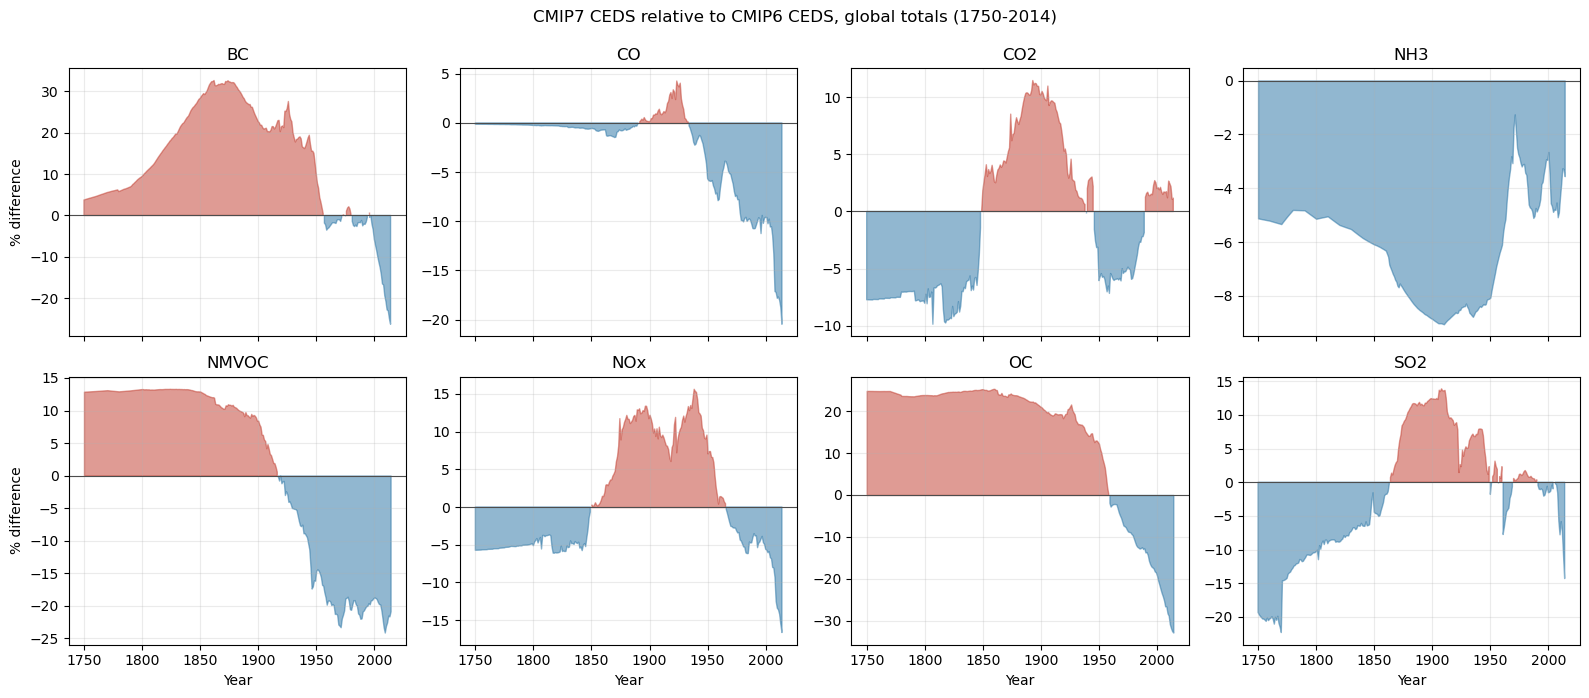

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)

for ax, species in zip(axes.flat, sorted(merged["species"].unique())):
    sub = merged[merged["species"] == species].sort_values("year")
    ax.fill_between(sub["year"], 0, sub["pct_diff"],
                    where=sub["pct_diff"] >= 0, alpha=0.5, color="#c0392b")
    ax.fill_between(sub["year"], 0, sub["pct_diff"],
                    where=sub["pct_diff"] < 0, alpha=0.5, color="#2471a3")
    ax.axhline(0, color="0.3", linewidth=0.8)
    ax.set_title(species)
    ax.grid(alpha=0.25)

for ax in axes[:, 0]:
    ax.set_ylabel("% difference")
for ax in axes[-1]:
    ax.set_xlabel("Year")

fig.suptitle("CMIP7 CEDS relative to CMIP6 CEDS, global totals (1750-2014)", y=0.99)
fig.tight_layout()
# fig.savefig(OUT / "pct_diff_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

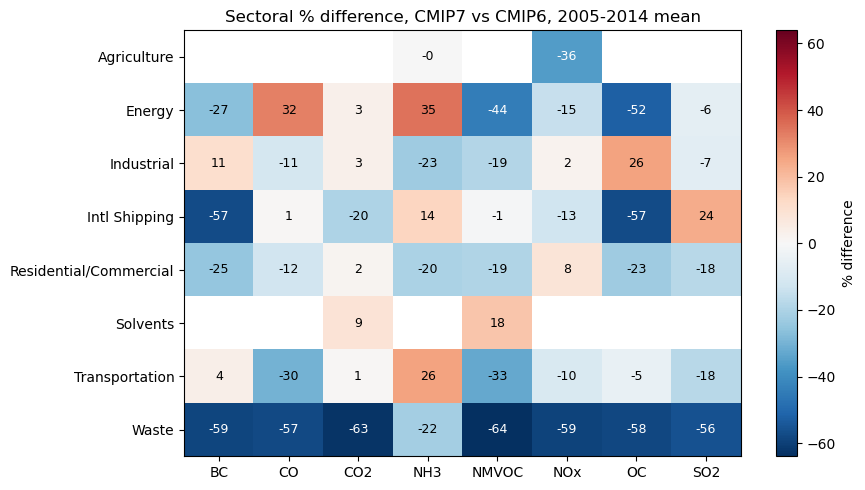

In [ ]:
import numpy as np

period = sect[sect["year"].between(2005, 2014)]
pivot = (period.assign(sector_name=lambda d: d["sector"].map(SECTORS))
         .pivot_table(index="sector_name", columns="species",
                      values="pct_diff", aggfunc="mean"))

fig, ax = plt.subplots(figsize=(9, 5))
lim = np.nanmax(np.abs(pivot.values))
im = ax.imshow(pivot.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")

ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)

for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > lim * 0.55 else "black")

ax.set_title("Sectoral % difference, CMIP7 vs CMIP6, 2005-2014 mean")
fig.colorbar(im, ax=ax, label="% difference")
fig.tight_layout()
# fig.savefig(OUT / "sectoral_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

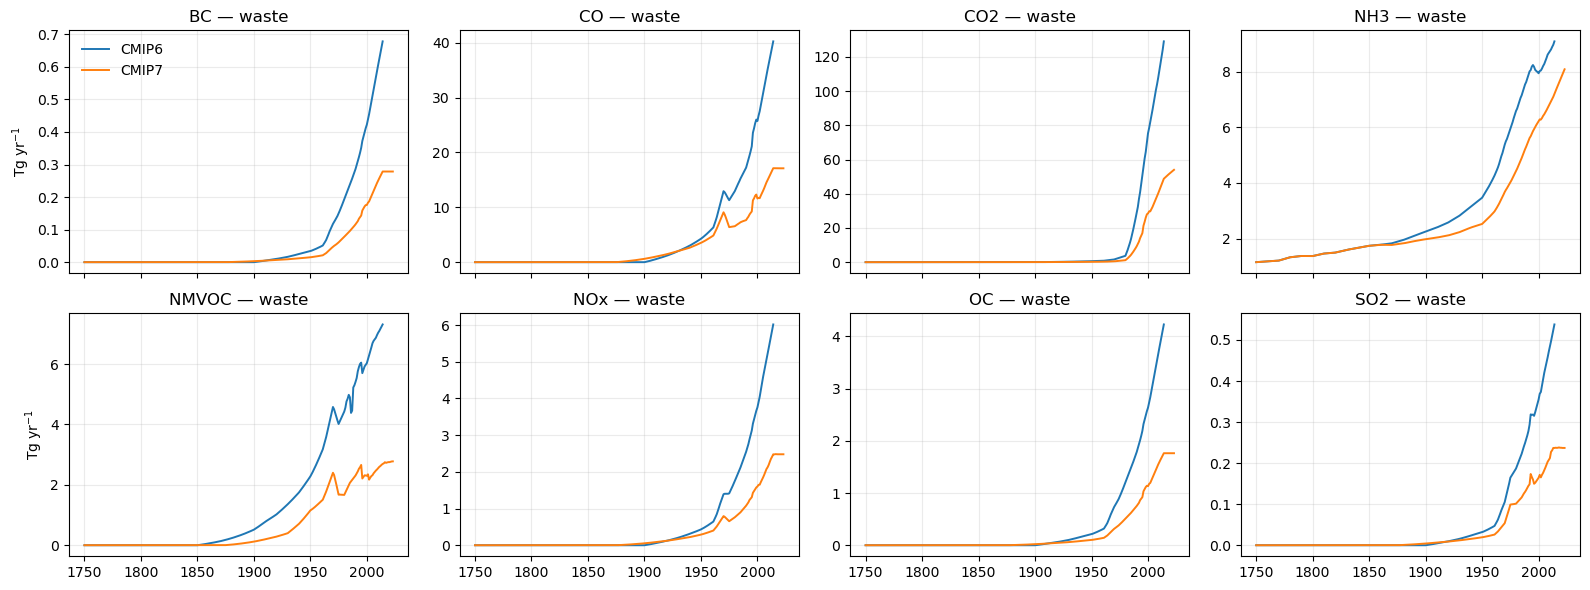

In [15]:
w6 = sector_totals(totals["cmip6"]); w6 = w6[w6["sector"] == 6]
w7 = sector_totals(totals["production"]); w7 = w7[w7["sector"] == 6]

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for ax, species in zip(axes.flat, sorted(w7["species"].unique())):
    a = w6[w6["species"] == species].sort_values("year")
    b = w7[w7["species"] == species].sort_values("year")
    ax.plot(a["year"], a["tg_yr"], label="CMIP6", linewidth=1.4)
    ax.plot(b["year"], b["tg_yr"], label="CMIP7", linewidth=1.4)
    ax.set_title(f"{species} — waste")
    ax.grid(alpha=0.25)
axes.flat[0].legend(frameon=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Tg yr$^{-1}$")
fig.tight_layout()
# fig.savefig(OUT / "waste_sector.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
def sectoral_table(sect, totals_a, totals_b, period,
                   min_share=0.01, min_tg=0.01):
    """Suppress cells where EITHER release is small. A percentage difference
    is meaningless when the denominator is near zero, which is why screening
    on one release alone leaves ratio artefacts behind."""
    lo, hi = period
    window = sect[sect["year"].between(lo, hi)]

    def _mag(df):
        m = (df[df["year"].between(lo, hi)]
             .groupby(["species", "sector"], as_index=False)["tg_per_year"].mean())
        g = m.groupby("species")["tg_per_year"].sum()
        m["share"] = m.apply(lambda r: r["tg_per_year"] / g[r["species"]], axis=1)
        return m[(m["share"] >= min_share) &
                 (m["tg_per_year"].abs() >= min_tg)][["species", "sector"]]

    keep = _mag(totals_a).merge(_mag(totals_b), on=["species", "sector"])

    return (window.merge(keep, on=["species", "sector"])
            .assign(sector_name=lambda d: d["sector"].map(SECTORS))
            .pivot_table(index="sector_name", columns="species",
                         values="pct_diff", aggfunc="mean").round(1))

for period in [(1840, 1860), (1890, 1910), (2005, 2014)]:
    print(f"\n{period[0]}-{period[1]}, sectors >=1% and >=0.01 Tg in BOTH releases:\n")
    print(sectoral_table(sect, totals["cmip6"], totals["production"], period).to_string())


1840-1860, sectors >=1% and >=0.01 Tg in BOTH releases:

species                   BC   CO   CO2   NH3  NMVOC   NOx    OC   SO2
sector_name                                                           
Agriculture              NaN  NaN   NaN -10.3    NaN -11.0   NaN   NaN
Energy                 -10.1  NaN  32.3   NaN   50.9  -1.9 -10.1 -63.5
Industrial              11.0 -9.4 -11.9   NaN    NaN   4.0   0.4  16.4
Intl Shipping            NaN  NaN   NaN   NaN    NaN  -0.2   NaN  -0.2
Residential/Commercial  31.8 -0.2  -4.8   1.2   -0.1  -0.3  26.4  -6.8
Transportation           NaN  NaN -45.2   NaN    NaN   NaN   NaN   NaN
Waste                    NaN  NaN   NaN  -0.1    NaN   NaN   NaN   NaN

1890-1910, sectors >=1% and >=0.01 Tg in BOTH releases:

species                   BC    CO   CO2   NH3  NMVOC   NOx    OC   SO2
sector_name                                                            
Agriculture              NaN   NaN   NaN  -8.7    NaN  -0.6   NaN   NaN
Energy                  -1.7 